# 07 · MLflow Experiment Tracking

Log parameters, metrics and artifacts for every experiment so results are reproducible and comparable. Backend: SQLite at `mlflow/mlflow.db` (override with `MLFLOW_TRACKING_URI`).

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


In [2]:
series = daily.set_index("date")["units"].astype(float)
train, test = series.iloc[:-HOLDOUT_DAYS], series.iloc[-HOLDOUT_DAYS:]

## 1. Configure tracking

In [3]:
import mlflow
from src import tracking
tracking.setup(True)
print("tracking uri:", mlflow.get_tracking_uri(), "| experiment:", tracking.EXPERIMENT_NAME)

tracking uri: sqlite:////home/claude/retailpulse-analytics-main/mlflow/mlflow.db | experiment: retailpulse


## 2. Track a small GBM hyper-parameter sweep

In [4]:
from src.forecasting.gbm import GBMForecaster
from src.forecasting.ensemble import regression_metrics
mlflow.set_experiment("retailpulse-gbm-sweep")
for depth in (3, 4, 6):
    for lr in (0.03, 0.08):
        with mlflow.start_run(run_name=f"gbm_d{depth}_lr{lr}"):
            mlflow.log_params({"max_depth": depth, "learning_rate": lr, "holdout_days": HOLDOUT_DAYS})
            fc = GBMForecaster(max_depth=depth, learning_rate=lr).fit(train).forecast(HOLDOUT_DAYS)
            mlflow.log_metrics(regression_metrics(test.values, fc["yhat"].values))
runs = mlflow.search_runs(experiment_names=["retailpulse-gbm-sweep"], order_by=["metrics.mae ASC"])
runs[["tags.mlflow.runName", "params.max_depth", "params.learning_rate", "metrics.mae", "metrics.wape"]].round(3)

2026/10/17 12:34:29 INFO mlflow.tracking.fluent: Experiment with name 'retailpulse-gbm-sweep' does not exist. Creating a new experiment.


,tags.mlflow.runName,params.max_depth,params.learning_rate,metrics.mae,metrics.wape
0,gbm_d4_lr0.03,4,0.03,14.614,0.114
1,gbm_d6_lr0.03,6,0.03,15.339,0.120
2,gbm_d3_lr0.03,3,0.03,15.496,0.121
3,gbm_d6_lr0.08,6,0.08,15.664,0.122
4,gbm_d4_lr0.08,4,0.08,18.051,0.141
5,gbm_d3_lr0.08,3,0.08,20.289,0.159


## 3. Log an artifact (plot) with the best run

best run: gbm_d4_lr0.03 | MAE 14.614


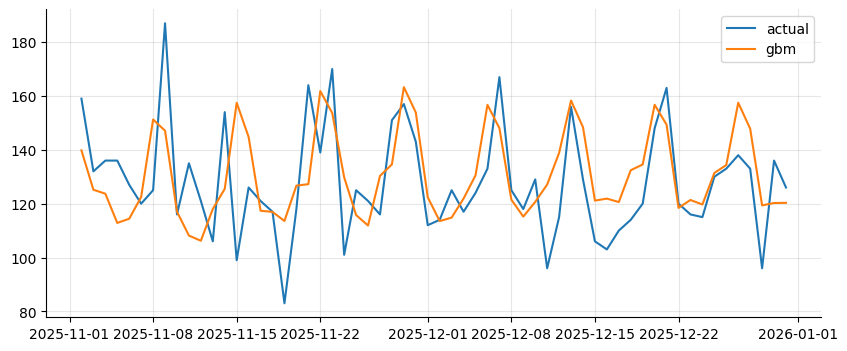

artifact logged


In [5]:
best = runs.iloc[0]
print("best run:", best["tags.mlflow.runName"], "| MAE", round(best["metrics.mae"], 3))
fc = GBMForecaster(max_depth=int(best["params.max_depth"]), learning_rate=float(best["params.learning_rate"])).fit(train).forecast(HOLDOUT_DAYS)
fig, ax = plt.subplots(); ax.plot(test.index, test.values, label="actual"); ax.plot(test.index, fc["yhat"], label="gbm"); ax.legend()
fig.savefig("/tmp/best_gbm.png", dpi=110); plt.show()
with mlflow.start_run(run_id=best["run_id"]):
    mlflow.log_artifact("/tmp/best_gbm.png")
print("artifact logged")

## 4. View the UI
Run `mlflow ui --backend-store-uri sqlite:///mlflow/mlflow.db` (or `docker compose -f docker/docker-compose.yml up mlflow`) and open http://localhost:5000.